# Проект: Дашборд конверсий
### Цель: создать прототип в Jupyter Notebook, загрузить данные и библиотеки, провести анализ полученных данных и создать графики и диаграммы на их основе.
#### * Перед каждой ячейкой кода размещено описание выполняемых действий и необходимые комментарии. Все действия выполнены согласно шагам в описании проекта.

#### 1. Загрузка библиотек

In [1]:
import os
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv

#### 2. Чтение файлов с Посещениями и Регистрациями

In [2]:
url_visits = 'https://drive.google.com/uc?export=download&id=1QosQQ4RRNR9rkL4t7sB707h2Uy0XfYJe'
url_registrations = 'https://drive.google.com/uc?export=download&id=1AeQz0kaSgz0lxYSDtuNm36muhy5fRCzZ'

visits = pd.read_csv(url_visits)
registrations = pd.read_csv(url_registrations)

#### 3. Первичный просмотр информации в файлах

In [3]:
print('visits:', visits.shape, ' registrations:', registrations.shape)
display(visits.head())
display(registrations.head())

visits: (1000, 4)  registrations: (1000, 5)


,uuid,platform,user_agent,date
0,1de9ea66-70d3-4a1f-8735-df5ef7697fb9,web,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_11_2...,2023-03-01T13:29:22
1,f149f542-e935-4870-9734-6b4501eaf614,web,Mozilla/5.0 (X11; CrOS x86_64 8172.45.0) Apple...,2023-03-01T16:44:28
2,f149f542-e935-4870-9734-6b4501eaf614,web,Mozilla/5.0 (X11; CrOS x86_64 8172.45.0) Apple...,2023-03-06T06:12:36
3,08f0ebd4-950c-4dd9-8e97-b5bdf073eed1,web,Mozilla/5.0 (X11; Ubuntu; Linux x86_64; rv:109...,2023-03-01T20:16:37
4,08f0ebd4-950c-4dd9-8e97-b5bdf073eed1,web,Mozilla/5.0 (X11; Ubuntu; Linux x86_64; rv:109...,2023-03-05T17:42:47


,date,user_id,email,platform,registration_type
0,2023-03-01T00:25:39,8838849,joseph95@example.org,web,google
1,2023-03-01T14:53:01,8741065,janetsuarez@example.net,web,yandex
2,2023-03-01T14:27:36,1866654,robert67@example.org,web,google
3,2023-03-01T02:42:34,1577584,elam@example.net,web,apple
4,2023-03-01T10:27:14,4765395,stephanie68@example.net,web,yandex


#### 4. Предварительный анализ с использованием .describe

In [4]:
display(visits.describe(include='all'))
display(registrations.describe(include='all'))

,uuid,platform,user_agent,date
count,1000,1000,1000,1000
unique,519,3,28,996
top,251a0926-ece3-4d77-aa42-ab569fdf9fe2,web,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,2023-03-01T08:01:45
freq,4,954,71,2


,date,user_id,email,platform,registration_type
count,1000,1.000000e+03,1000,1000,1000
unique,1000,NaN,997,3,4
top,2023-03-01T00:25:39,NaN,zanderson@example.org,android,email
freq,1,NaN,2,517,446
mean,NaN,4.488623e+06,NaN,NaN,NaN
std,NaN,2.620568e+06,NaN,NaN,NaN
min,NaN,2.236800e+04,NaN,NaN,NaN
25%,NaN,2.235489e+06,NaN,NaN,NaN
50%,NaN,4.473044e+06,NaN,NaN,NaN
75%,NaN,6.779707e+06,NaN,NaN,NaN


#### 5. Периоды и распределение данных

In [5]:
print(visits['platform'].value_counts(), '\n')
print(registrations['platform'].value_counts(), '\n')
print(registrations['registration_type'].value_counts(), '\n')
 
print('Визиты:', visits['date'].min(), '->', visits['date'].max())
print('Регистрации:', registrations['date'].min(), '->', registrations['date'].max())

platform
web        954
android     27
ios         19
Name: count, dtype: int64 

platform
android    517
web        265
ios        218
Name: count, dtype: int64 

registration_type
email     446
google    303
apple     178
yandex     73
Name: count, dtype: int64 

Визиты: 2023-03-01T00:05:35 -> 2023-03-07T23:05:08
Регистрации: 2023-03-01T00:12:22 -> 2023-03-05T22:04:01


### 6. Промежуточные выводы:
##### - В таблице Посещений 1000 записей, Регистраций - 1000.
##### - Платформы Посещений: web > 95%, android, ios, Регистраций: android > 50%, web ~ 26%, ios ~ 21%.
##### - Типы регистраций: email ~ 45%, google ~ 30%, apple ~ 18%, yandex ~ 7%
##### - Периоды Посещений: 01.03.2023 - 07.03.2023, Регистраций: 01.03.2023 - 05.03.2023 (данные из сохраненных файлов, не полученных по API)

#### 7. Создание файла .env с маршрутом для API и ограничением по периоду

In [6]:
from pathlib import Path

content = (
    "API_URL=https://data-charts-api.hexlet.app\n"
    "DATE_BEGIN=2023-03-01\n"
    "DATE_END=2023-09-01\n"
)

Path('.env').write_text(content, encoding='utf-8')
print('Создан файл:', Path('.env').resolve())

Создан файл: C:\Users\Анастасия\project\.env


#### 8. Проверка переменных окружения

In [7]:
from dotenv import load_dotenv
import os

load_dotenv(override=True)

print(os.getenv('API_URL'), os.getenv('DATE_BEGIN'), os.getenv('DATE_END'))

https://data-charts-api.hexlet.app 2023-03-01 2023-09-01


#### 9. Параметры запроса из файла .env

In [8]:
API_URL = os.getenv('API_URL')
DATE_BEGIN = os.getenv('DATE_BEGIN')
DATE_END = os.getenv('DATE_END')
 
print(API_URL, DATE_BEGIN, DATE_END)


https://data-charts-api.hexlet.app 2023-03-01 2023-09-01


#### 10. Запросы к API

In [9]:
resp_visits = requests.get(
    f'{API_URL}/visits',
    params={'begin': DATE_BEGIN, 'end': DATE_END},
)
 
resp_registrations = requests.get(
    f'{API_URL}/registrations',
    params={'begin': DATE_BEGIN, 'end': DATE_END},
)
print(resp_visits.status_code, resp_registrations.status_code)
 
visits = pd.DataFrame(resp_visits.json())
registrations = pd.DataFrame(resp_registrations.json())
visits.shape, registrations.shape

200 200


((263459, 4), (21836, 5))

#### 11. Приведение формата времени к datetime

In [10]:
visits['datetime'] = pd.to_datetime(visits['datetime'])
registrations['datetime'] = pd.to_datetime(registrations['datetime'])
 
visits.head()


,visit_id,platform,user_agent,datetime
0,e06425d2-094d-41d8-bfd4-c1824a67dbcd,ios,Mozilla/5.0 (iPhone; CPU iPhone OS 16_1_1 like...,2023-04-01 00:16:25
1,16842b59-23f6-49c3-b0a6-95c1c20f9951,ios,Mozilla/5.0 (iPhone; CPU iPhone OS 17_0_3 like...,2023-04-01 22:57:29
2,fb701758-13da-42fe-8130-15dd8403ebbc,ios,Mozilla/5.0 (iPhone; CPU iPhone OS 15_8 like M...,2023-04-01 06:21:03
3,3e654a1a-18a9-44fe-82ee-549cafb21df3,ios,Mozilla/5.0 (iPhone; CPU iPhone OS 15_8 like M...,2023-04-01 20:58:37
4,dafb376f-3c56-4c8d-a6da-891e3f297951,ios,Mozilla/5.0 (iPhone; CPU iPhone OS 17_0_3 like...,2023-04-01 12:58:48


#### 12. Удаление ботов из выборки

In [11]:
visits_wo_bots = visits[~visits['user_agent'].str.contains('bot', case=False, na=False)]

#### 13. Последнее посещение для каждого visit_id

In [12]:
last_visits = (
    visits_wo_bots
    .sort_values('datetime')
    .drop_duplicates(subset='visit_id', keep='last')
)

#### 14. Группировка посещений по дате и платформе

In [13]:
visits_grouped = (
    last_visits
    .assign(date_group=last_visits['datetime'].dt.normalize())
    .groupby(['date_group', 'platform'])
    .size()
    .reset_index(name='visits')
)
 
visits_grouped.head()

,date_group,platform,visits
0,2023-03-01,android,75
1,2023-03-01,ios,22
2,2023-03-01,web,279
3,2023-03-02,android,67
4,2023-03-02,ios,31


#### 15. Группировка регистраций по дате и платформе

In [14]:
registrations_grouped = (
    registrations
    .assign(date_group=registrations['datetime'].dt.normalize())
    .groupby(['date_group', 'platform'])
    .size()
    .reset_index(name='registrations')
)
 
registrations_grouped.head()

,date_group,platform,registrations
0,2023-03-01,android,61
1,2023-03-01,ios,18
2,2023-03-01,web,8
3,2023-03-02,android,59
4,2023-03-02,ios,24


#### 16. Объединение датафреймов, расчет конверсий и создание файла conversion.json

In [15]:
conversion = visits_grouped.merge(
    registrations_grouped,
    on=['date_group', 'platform'],
    how='outer',
).fillna(0)
 
conversion['visits'] = conversion['visits'].astype(int)
conversion['registrations'] = conversion['registrations'].astype(int)
conversion['conversion'] = conversion['registrations'] / conversion['visits'] * 100
 
conversion = conversion.sort_values('date_group').reset_index(drop=True)
 
conversion.to_json('./conversion.json')
conversion.head()

C:\Users\Анастасия\AppData\Local\Temp\ipykernel_7412\1127499253.py:13: Pandas4Warning: The default 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  conversion.to_json('./conversion.json')


,date_group,platform,visits,registrations,conversion
0,2023-03-01,android,75,61,81.333333
1,2023-03-01,ios,22,18,81.818182
2,2023-03-01,web,279,8,2.867384
3,2023-03-02,android,67,59,88.059701
4,2023-03-02,ios,31,24,77.419355


#### 17. Проверка платформ (остались web, ios, android) и отсутствие строк без посещеий

In [16]:
print(conversion['platform'].unique())
print('строк с visits == 0:', (conversion['visits'] == 0).sum())

<StringArray>
['android', 'ios', 'web']
Length: 3, dtype: str
строк с visits == 0: 0


#### 18. Добавление реклам: чтение файла, выборка даты без времени

In [17]:
ads = pd.read_csv('./data/ads.csv')
 
ads['date_group'] = pd.to_datetime(ads['date']).dt.normalize()
 
ads_grouped = (
    ads
    .groupby('date_group')
    .agg(cost=('cost', 'sum'), utm_campaign=('utm_campaign', 'first'))
    .reset_index()
)
 
ads_grouped.head()

,date_group,cost,utm_campaign
0,2023-03-01,212,advanced_algorithms_series
1,2023-03-02,252,advanced_algorithms_series
2,2023-03-03,202,advanced_algorithms_series
3,2023-03-04,223,advanced_algorithms_series
4,2023-03-05,265,advanced_algorithms_series


#### 19. Ежедневные итоги визитов и регистраций

In [18]:
daily_totals = (
    conversion
    .groupby('date_group')
    .agg(visits=('visits', 'sum'), registrations=('registrations', 'sum'))
    .reset_index()
)
 
daily_totals.head()

,date_group,visits,registrations
0,2023-03-01,376,87
1,2023-03-02,613,106
2,2023-03-03,683,107
3,2023-03-04,647,159
4,2023-03-05,707,115


#### 20. Объединение датафреймов с данными по рекламе и сохранение файла ads.json

In [19]:
ads_report = daily_totals.merge(ads_grouped, on='date_group', how='left')
 
ads_report['cost'] = ads_report['cost'].fillna(0)
ads_report['utm_campaign'] = ads_report['utm_campaign'].fillna('none')
 
ads_report = (
    ads_report[['date_group', 'visits', 'registrations', 'cost', 'utm_campaign']]
    .sort_values('date_group')
    .reset_index(drop=True)
)
 
ads_report.to_json('./ads.json')
ads_report.head(10)

C:\Users\Анастасия\AppData\Local\Temp\ipykernel_7412\2735418934.py:12: Pandas4Warning: The default 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  ads_report.to_json('./ads.json')


,date_group,visits,registrations,cost,utm_campaign
0,2023-03-01,376,87,212.0,advanced_algorithms_series
1,2023-03-02,613,106,252.0,advanced_algorithms_series
2,2023-03-03,683,107,202.0,advanced_algorithms_series
3,2023-03-04,647,159,223.0,advanced_algorithms_series
4,2023-03-05,707,115,265.0,advanced_algorithms_series
5,2023-03-06,1291,230,108.0,advanced_algorithms_series
6,2023-03-07,1382,124,165.0,advanced_algorithms_series
7,2023-03-08,1382,151,155.0,advanced_algorithms_series
8,2023-03-09,1064,209,124.0,advanced_algorithms_series
9,2023-03-10,812,112,276.0,advanced_algorithms_series


#### 21. Подготовка папки для визуализации

In [20]:
os.makedirs('./charts', exist_ok=True)
 
sns.set()

#### 22. Данные для графиков

In [21]:
daily_visits = conversion.groupby('date_group')['visits'].sum()
daily_registrations = conversion.groupby('date_group')['registrations'].sum()
mean_conversion = conversion.groupby('date_group')['conversion'].mean()
 
visits_by_platform = conversion.pivot(index='date_group', columns='platform', values='visits')
registrations_by_platform = conversion.pivot(index='date_group', columns='platform', values='registrations')
conversion_by_platform = conversion.pivot(index='date_group', columns='platform', values='conversion')

#### 23. График 1: Итоговые посещения

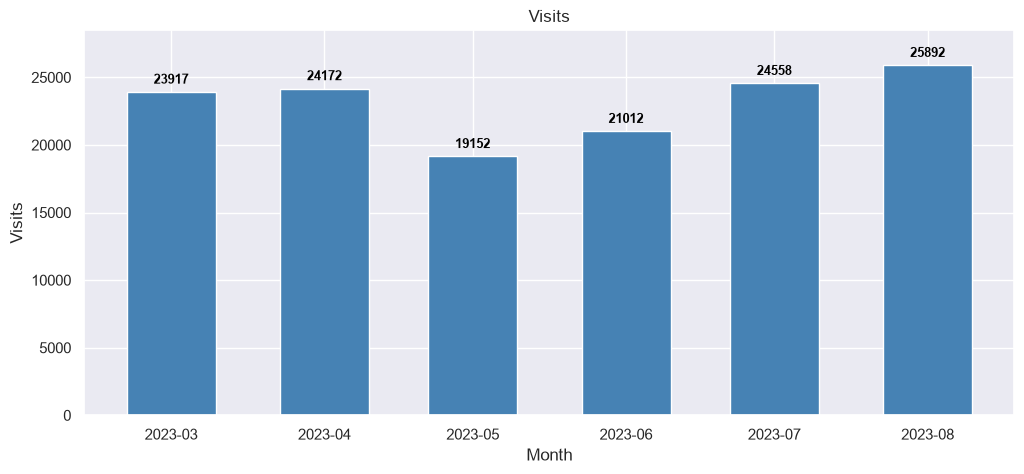

In [22]:
monthly_visits = daily_visits.resample('MS').sum()

plt.figure(figsize=(12, 5))
plt.bar(monthly_visits.index, monthly_visits.values,
        width=18, color='steelblue')

for date, value in monthly_visits.items():
    plt.annotate(f'{value:.0f}',
                 xy=(date, value),
                 xytext=(0, 6),
                 textcoords='offset points',
                 ha='center', fontsize=9, color='black',
                 fontweight='bold')

plt.ylim(0, monthly_visits.max() * 1.1)
plt.title('Visits')
plt.xlabel('Month')
plt.ylabel('Visits')
plt.savefig('./charts/visits_dynamic.png')
plt.show()

#### 24. График 2: Посещения по платформам

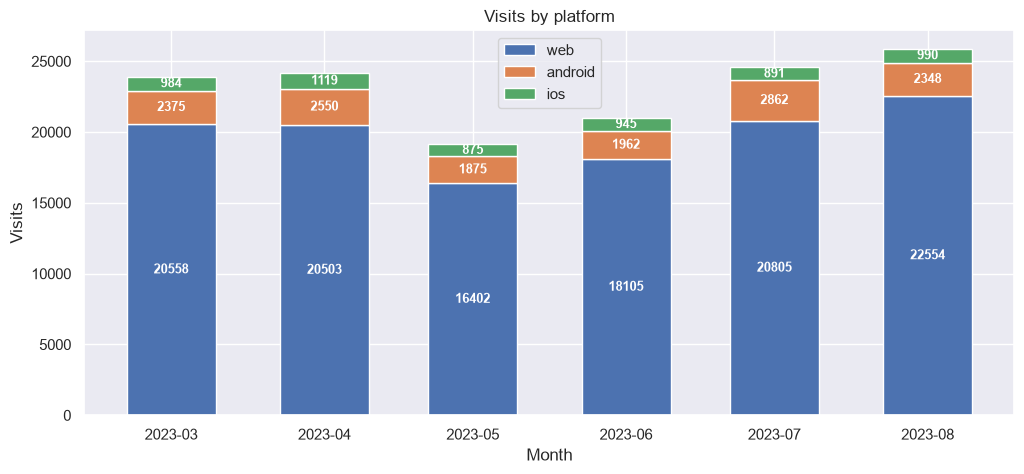

In [23]:
monthly_by_platform = visits_by_platform.resample('MS').sum()

plt.figure(figsize=(12, 5))
bottom = None
for platform in ['web', 'android', 'ios']:
    values = monthly_by_platform[platform].fillna(0)
    plt.bar(monthly_by_platform.index, values, width=18, bottom=bottom, label=platform)
    for date, value in values.items():
        if value > 0:
            base = 0 if bottom is None else bottom.loc[date]
            plt.annotate(f'{value:.0f}',
                         xy=(date, base + value / 2),
                         ha='center', va='center',
                         fontsize=9, color='white',
                         fontweight='bold')
    bottom = values if bottom is None else bottom + values

plt.title('Visits by platform')
plt.xlabel('Month')
plt.ylabel('Visits')
plt.legend()
plt.savefig('./charts/visits_by_platform.png')
plt.show()

#### 25. График 3: Итоговые регистрации

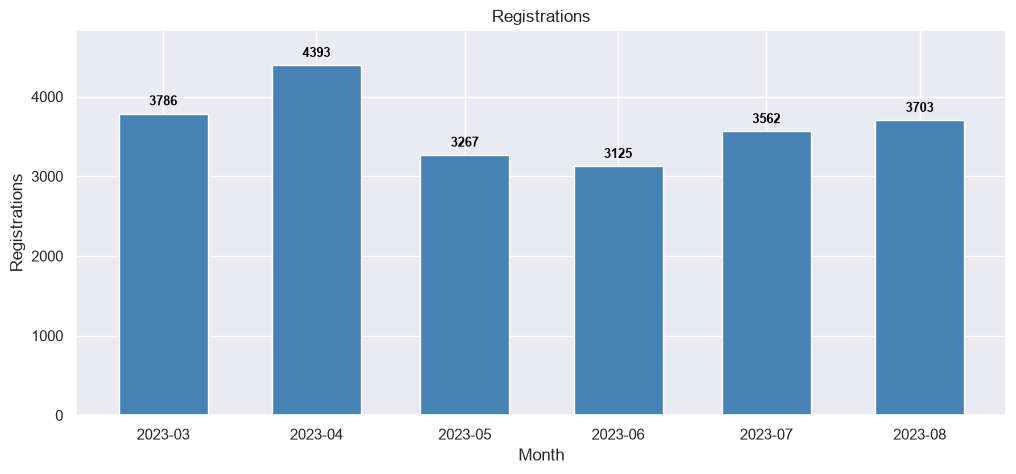

In [24]:
monthly_registrations = daily_registrations.resample('MS').sum()

plt.figure(figsize=(12, 5))
plt.bar(monthly_registrations.index, monthly_registrations.values,
        width=18, color='steelblue')

for date, value in monthly_registrations.items():
    plt.annotate(f'{value:.0f}',
                 xy=(date, value),
                 xytext=(0, 6),
                 textcoords='offset points',
                 ha='center', fontsize=9, color='black',
                 fontweight='bold')

plt.ylim(0, monthly_registrations.max() * 1.1)
plt.title('Registrations')
plt.xlabel('Month')
plt.ylabel('Registrations')
plt.savefig('./charts/registrations_dynamic.png')
plt.show()

#### 26. График 4: Регистрации по платформам

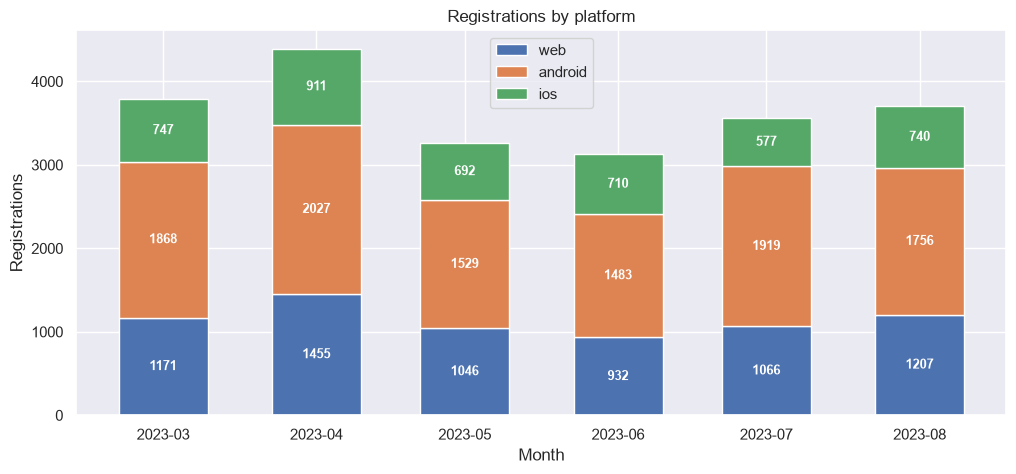

In [25]:
monthly_reg_by_platform = registrations_by_platform.resample('MS').sum()

plt.figure(figsize=(12, 5))
bottom = None
for platform in ['web', 'android', 'ios']:
    values = monthly_reg_by_platform[platform].fillna(0)
    plt.bar(monthly_reg_by_platform.index, values, width=18, bottom=bottom, label=platform)
    for date, value in values.items():
        if value > 0:
            base = 0 if bottom is None else bottom.loc[date]
            plt.annotate(f'{value:.0f}',
                         xy=(date, base + value / 2),
                         ha='center', va='center',
                         fontsize=9, color='white',
                         fontweight='bold')
    bottom = values if bottom is None else bottom + values

plt.title('Registrations by platform')
plt.xlabel('Month')
plt.ylabel('Registrations')
plt.legend()
plt.savefig('./charts/registrations_by_platform.png')
plt.show()

#### 27. График 5: Конверсия по каждой платформе

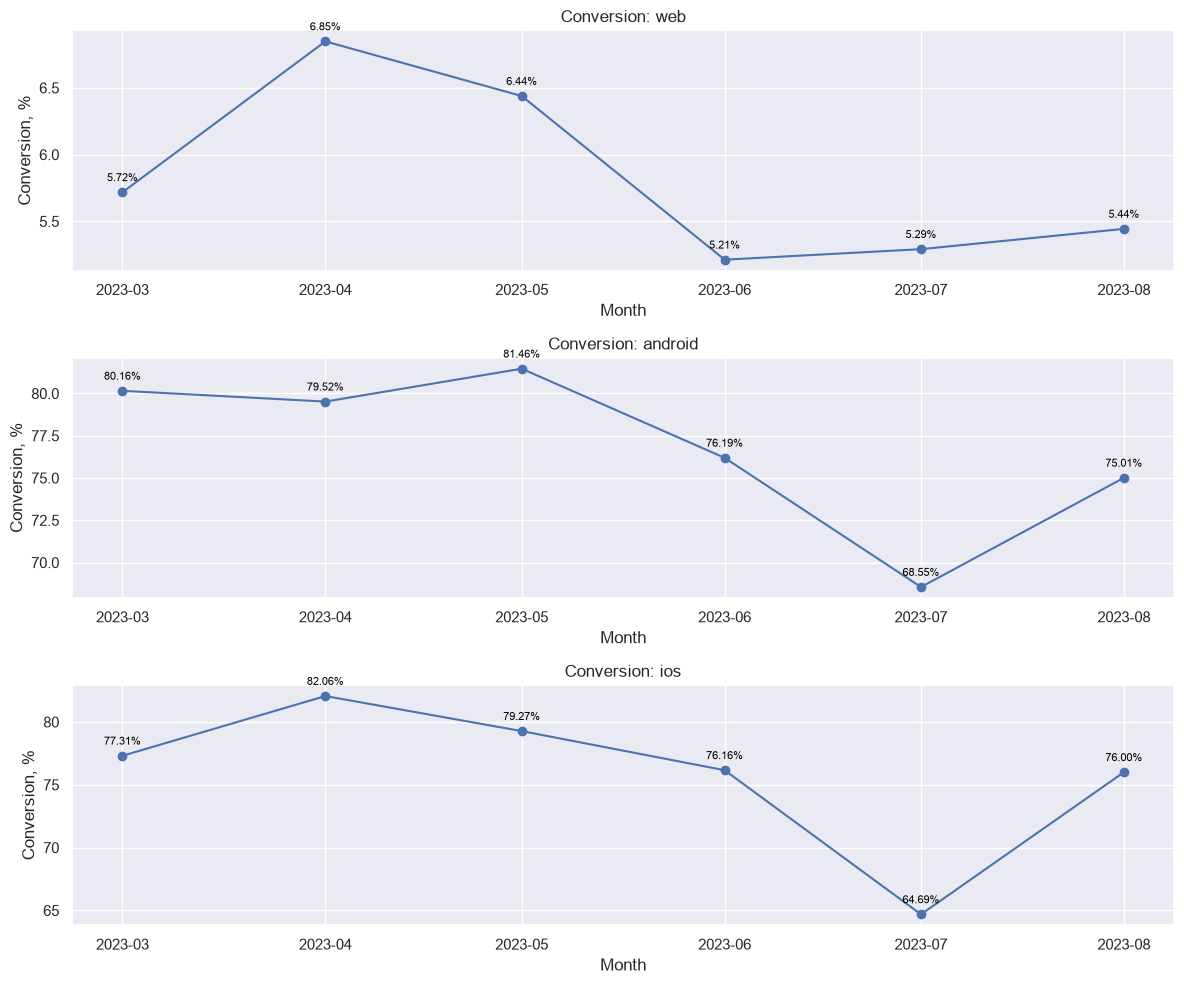

In [26]:
monthly_conv_by_platform = conversion_by_platform.resample('MS').mean()

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

for ax, platform in zip(axes, ['web', 'android', 'ios']):
    values = monthly_conv_by_platform[platform]
    ax.plot(values.index, values.values, marker='o', markersize=6)
    for date, value in values.items():
        ax.annotate(f'{value:.2f}%',
                    xy=(date, value),
                    xytext=(0, 8),
                    textcoords='offset points',
                    ha='center', fontsize=8, color='black')
    ax.set_title(f'Conversion: {platform}')
    ax.set_xlabel('Month')
    ax.set_ylabel('Conversion, %')

plt.tight_layout()
plt.savefig('./charts/conversion_by_platform.png')
plt.show()

#### 28. График 6: Средняя конверсия

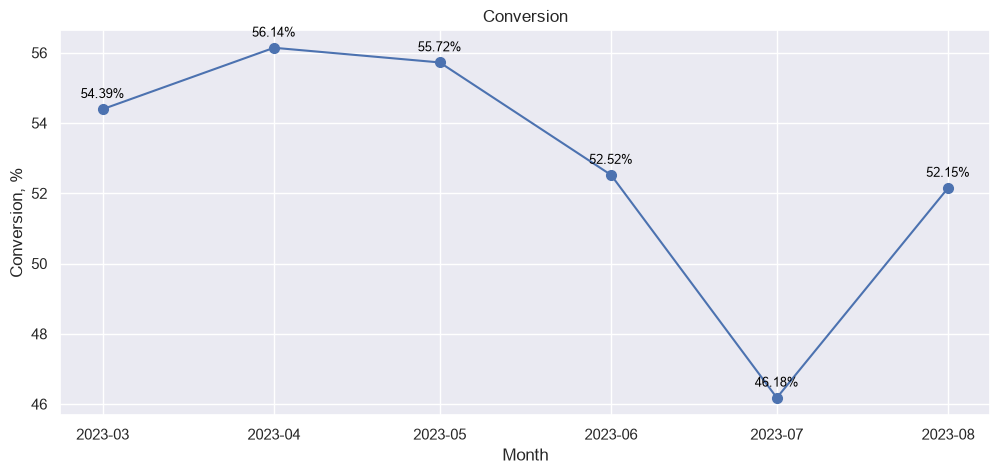

In [27]:
monthly_conversion = mean_conversion.resample('MS').mean()

plt.figure(figsize=(12, 5))
plt.plot(monthly_conversion.index, monthly_conversion.values,
         marker='o', markersize=7)

for date, value in monthly_conversion.items():
    plt.annotate(f'{value:.2f}%',
                 xy=(date, value),
                 xytext=(0, 8),
                 textcoords='offset points',
                 ha='center', fontsize=9, color='black')

plt.title('Conversion')
plt.xlabel('Month')
plt.ylabel('Conversion, %')
plt.savefig('./charts/mean_conversion.png')
plt.show()

#### 29. График 7: Стоимость реклам

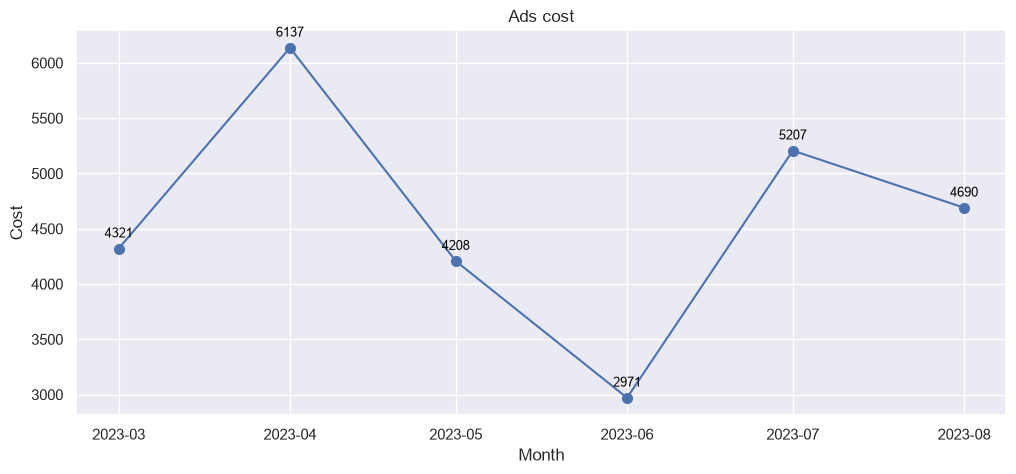

In [28]:
monthly_cost = ads_report.set_index('date_group')['cost'].resample('MS').sum()

plt.figure(figsize=(12, 5))
plt.plot(monthly_cost.index, monthly_cost.values,
         marker='o', markersize=7)

for date, value in monthly_cost.items():
    plt.annotate(f'{value:.0f}',
                 xy=(date, value),
                 xytext=(0, 8),
                 textcoords='offset points',
                 ha='center', fontsize=9, color='black')

plt.title('Ads cost')
plt.xlabel('Month')
plt.ylabel('Cost')
plt.savefig('./charts/ads_cost.png')
plt.show()


#### 30. График 8: Визиты с выделением рекламных кампаний

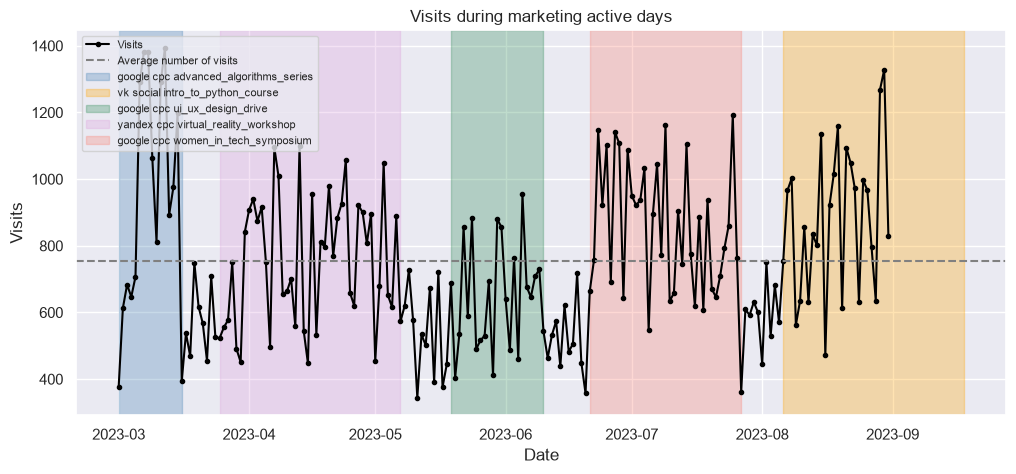

In [29]:
campaigns = (
    ads
    .groupby('utm_campaign')
    .agg(start=('date_group', 'min'),
         end=('date_group', 'max'),
         source=('utm_source', 'first'),
         medium=('utm_medium', 'first'))
    .reset_index()
)

colors = ['steelblue', 'orange', 'seagreen', 'plum', 'salmon', 'gold']

plt.figure(figsize=(12, 5))
plt.plot(daily_visits.index, daily_visits.values, color='black',
         marker='o', markersize=3, label='Visits')
plt.axhline(daily_visits.mean(), color='gray', linestyle='--',
            label='Average number of visits')

for i, row in campaigns.iterrows():
    plt.axvspan(row['start'], row['end'] + pd.Timedelta(days=1),
                color=colors[i % len(colors)], alpha=0.3,
                label=f"{row['source']} {row['medium']} {row['utm_campaign']}")

plt.title('Visits during marketing active days')
plt.xlabel('Date')
plt.ylabel('Visits')
plt.legend(loc='upper left', fontsize=8)
plt.grid(True)
plt.savefig('./charts/visits_ads.png')
plt.show()

#### 31. График 9: Регистрации с выделением рекламных кампаний

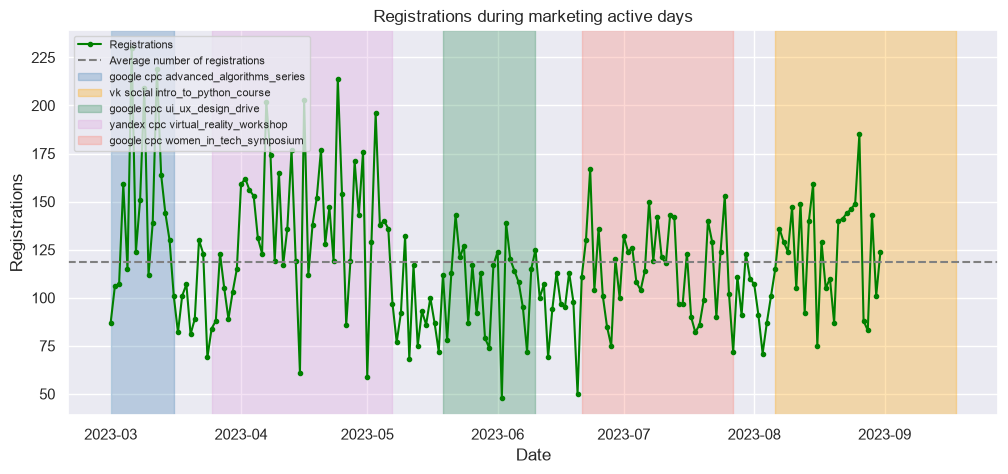

In [30]:
campaigns = (
    ads
    .groupby('utm_campaign')
    .agg(start=('date_group', 'min'),
         end=('date_group', 'max'),
         source=('utm_source', 'first'),
         medium=('utm_medium', 'first'))
    .reset_index()
)

colors = ['steelblue', 'orange', 'seagreen', 'plum', 'salmon', 'gold']

plt.figure(figsize=(12, 5))
plt.plot(daily_registrations.index, daily_registrations.values, color='green',
         marker='o', markersize=3, label='Registrations')
plt.axhline(daily_registrations.mean(), color='gray', linestyle='--',
            label='Average number of registrations')

for i, row in campaigns.iterrows():
    plt.axvspan(row['start'], row['end'] + pd.Timedelta(days=1),
                color=colors[i % len(colors)], alpha=0.3,
                label=f"{row['source']} {row['medium']} {row['utm_campaign']}")

plt.title('Registrations during marketing active days')
plt.xlabel('Date')
plt.ylabel('Registrations')
plt.legend(loc='upper left', fontsize=8)
plt.grid(True)
plt.savefig('./charts/registrations_ads.png')
plt.show()

## Вывод:
#### - Больше всего посещений приносит web платформа, при этом в части регистраций лидирует android. Меньшую часть в визитах и регистрациях занимает платформа ios. Пропорция между платформами в визитах и регистрациях сохраняется от месяца к месяцу.
#### - Наибольшее количество визитов - в августе, регистраций - в апреле, при этом самые низкие показатели для визитов и регистраций зафиксированы в мае и июне.
#### - Максимальная средняя конверсия зафиксирована в апреле, лучшие месяцы - с марта по май, летом наблюдается снижение с минимумом в июле и последующим ростом в августе. Тренд со снижением в летний период наблюдается по мобильным платформам android и ios, для последней зафиксирован максимум в апреле - более 82%. Общий процент конверсии высокий за счет мобильных платформ, которые кратно выше web платформы.
#### - Самые большие затраты на рекламу - в апреле, самые низкие - в июне. 
#### - Снижение визитов наблюдается в период между рекламными компаниями. Рост визитов и регистраций отмечается в месяц самой затратной кампании, также наблюдается рост конверсии в августе в виду запуска очередной кампании в июле после снижения конверсии.